# Kontextualisierte Embeddings: dasselbe Wort, zwei Bedeutungen

**Didaktisches Ziel:** *Vor Self-Attention hat ein Token überall denselben Vektor. Danach trägt der Vektor die Bedeutung aus dem Satz.*

Dieses Notebook gehört zur Folie **„Kontextualisierte Embeddings vor und nach Self-Attention“**. Als Beispiel dient das mehrdeutige Wort **„Bank“**:

- *„Park sitzen auf der Bank“* → Sitzbank
- *„Geld sparen auf der Bank“* → Geldinstitut

Ablauf:

1. Ein Spielzeug-Beispiel mit 4 Dimensionen, das man von Hand nachrechnen kann
2. Der Bezug zum Rechenbeispiel „von“ aus dem Skript
3. *(Optional)* Dieselbe Frage an ein echtes deutsches Sprachmodell (GPT-2)

> Wie Q, K, V und die Softmax im Detail gerechnet werden, zeigt `attention_rechenbeispiel.ipynb`. Hier geht es darum, **was mit den Vektoren passiert**.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)

def softmax(z, axis=-1):
    z = z - np.max(z, axis=axis, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=axis, keepdims=True)

def cos_sim(a, b):
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b)))

## 1) Statische Embeddings (vor Self-Attention)

Vier benannte Dimensionen zur Anschauung: **Natur**, **Finanzen**, **Sitzen**, **Funktionswort**.

„Bank“ bekommt einen Vektor, der beide Bedeutungen gleichzeitig andeutet. Das Modell weiß beim Nachschlagen in der Embedding-Matrix ja noch nicht, welche gemeint ist.
Zusätzlich gibt es zwei **Referenzwörter**, mit denen wir später vergleichen: „Sofa“ (Sitzmöbel) und „Konto“ (Finanzen).

In [2]:
dims = ["Natur", "Finanzen", "Sitzen", "Funktion"]

emb = {
    "Park":   [2.0, 0.0, 0.5, 0.0],
    "sitzen": [0.5, 0.0, 2.0, 0.0],
    "Geld":   [0.0, 2.0, 0.0, 0.0],
    "sparen": [0.0, 2.0, 0.0, 0.5],
    "auf":    [0.0, 0.0, 0.0, 1.0],
    "der":    [0.0, 0.0, 0.0, 1.0],
    "Bank":   [0.7, 0.7, 0.7, 0.0],   # mehrdeutig
    # Referenzwörter (kommen in den Sätzen nicht vor)
    "Sofa":   [0.3, 0.0, 2.0, 0.0],
    "Konto":  [0.0, 2.0, 0.0, 0.2],
}
emb = {w: np.array(v) for w, v in emb.items()}

satz_A = ["Park", "sitzen", "auf", "der", "Bank"]
satz_B = ["Geld", "sparen", "auf", "der", "Bank"]

x_bank = emb["Bank"]
print("Bank (statisch):", x_bank)
print(f"Ähnlichkeit zu Sofa:  {cos_sim(x_bank, emb['Sofa']):.2f}")
print(f"Ähnlichkeit zu Konto: {cos_sim(x_bank, emb['Konto']):.2f}")

Bank (statisch): [0.7 0.7 0.7 0. ]
Ähnlichkeit zu Sofa:  0.66
Ähnlichkeit zu Konto: 0.57


Statisch liegt „Bank“ ungefähr gleich weit von „Sofa“ und „Konto“ entfernt. In beiden Sätzen startet „Bank“ mit **genau demselben** Vektor.

## 2) Eine Schicht Self-Attention

Wir halten die Rechnung bewusst einfach:

- $W_Q = W_K = W_V = I$, damit zählt nur die Ähnlichkeit der Embeddings selbst
- **Causal Mask:** Jedes Token sieht nur sich selbst und die Tokens davor (wie in GPT)
- **Residual-Verbindung:** Das Ergebnis der Attention wird zum ursprünglichen Vektor **addiert**: $h = x + \text{Attention}(x)$

$$
\text{Score}_{ij} = \frac{x_i \cdot x_j}{\sqrt{d}}, \qquad
\alpha_{ij} = \mathrm{softmax}_j(\text{Score}_{ij}), \qquad
h_i = x_i + \sum_j \alpha_{ij}\, x_j
$$

In [3]:
def self_attention(tokens):
    X = np.stack([emb[t] for t in tokens])
    n, d = X.shape
    S = X @ X.T / np.sqrt(d)
    maske = np.tril(np.ones((n, n), dtype=bool))      # nur Vergangenheit + sich selbst
    S = np.where(maske, S, -np.inf)
    A = softmax(S, axis=1)
    H = X + A @ X                                     # Residual
    return X, A, H

X_A, A_A, H_A = self_attention(satz_A)
X_B, A_B, H_B = self_attention(satz_B)

**Von Hand für „Bank“ in Satz A** ($\sqrt{d} = 2$):

| Token | $x_{\text{Bank}} \cdot x_j$ | Score | $e^{\text{Score}}$ | $\alpha$ |
| :--- | :---: | :---: | :---: | :---: |
| Park | $0.7\cdot2 + 0.7\cdot0.5 = 1.75$ | 0.875 | 2.399 | 0.270 |
| sitzen | $0.7\cdot0.5 + 0.7\cdot2 = 1.75$ | 0.875 | 2.399 | 0.270 |
| auf | 0 | 0 | 1.000 | 0.113 |
| der | 0 | 0 | 1.000 | 0.113 |
| Bank | $3 \cdot 0.49 = 1.47$ | 0.735 | 2.085 | 0.235 |
| | | | Summe 8.883 | |

„Bank“ achtet am stärksten auf „Park“ und „sitzen“. Die Funktionswörter bekommen wenig Gewicht, weil sie keine gemeinsame Dimension mit „Bank“ haben.

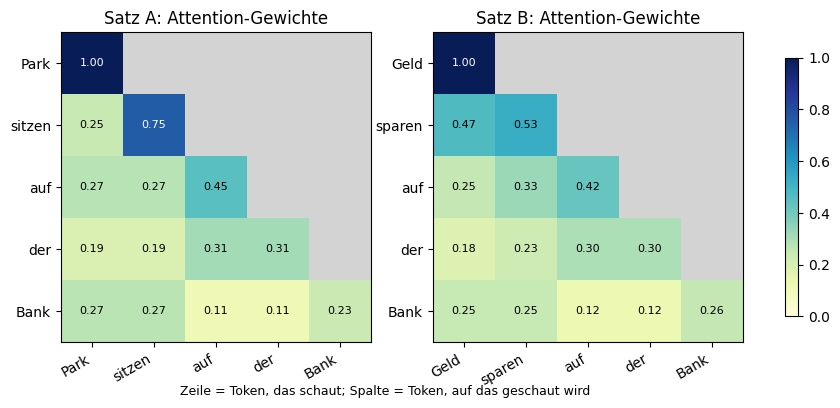

Bank in Satz A achtet auf: {'Park': 0.27, 'sitzen': 0.27, 'auf': 0.113, 'der': 0.113, 'Bank': 0.235}
Bank in Satz B achtet auf: {'Geld': 0.248, 'sparen': 0.248, 'auf': 0.123, 'der': 0.123, 'Bank': 0.257}


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, tokens, A, titel in [(axes[0], satz_A, A_A, "Satz A"), (axes[1], satz_B, A_B, "Satz B")]:
    cmap = plt.get_cmap("YlGnBu").copy()
    cmap.set_bad("lightgray")
    maskiert = np.ma.masked_where(np.triu(np.ones_like(A, dtype=bool), k=1), A)
    im = ax.imshow(maskiert, cmap=cmap, vmin=0, vmax=1)
    ax.set_xticks(range(len(tokens)), tokens, rotation=30, ha="right")
    ax.set_yticks(range(len(tokens)), tokens)
    for i in range(len(tokens)):
        for j in range(len(tokens)):
            if j <= i:
                ax.text(j, i, f"{A[i, j]:.2f}", ha="center", va="center", fontsize=8,
                        color="white" if A[i, j] > 0.6 else "black")
    ax.set_title(f"{titel}: Attention-Gewichte")
fig.colorbar(im, ax=axes, shrink=0.8)
fig.text(0.42, 0.0, "Zeile = Token, das schaut; Spalte = Token, auf das geschaut wird", ha="center", fontsize=9)
plt.show()

print("Bank in Satz A achtet auf:", dict(zip(satz_A, A_A[-1].round(3))))
print("Bank in Satz B achtet auf:", dict(zip(satz_B, A_B[-1].round(3))))

Das graue obere Dreieck ist die **Causal Mask**. „Park“ in der ersten Zeile kann nur auf sich selbst schauen und bekommt deshalb das Gewicht 1.

## 3) Vorher und nachher

In [5]:
h_A = H_A[-1]
h_B = H_B[-1]

print(f"{'':<22} {'Vektor':<28} {'zu Sofa':>8} {'zu Konto':>9}")
for name, v in [("Bank statisch", x_bank), ("Bank in Satz A (Park)", h_A), ("Bank in Satz B (Geld)", h_B)]:
    print(f"{name:<22} {str(v.round(3)):<28} {cos_sim(v, emb['Sofa']):>8.2f} {cos_sim(v, emb['Konto']):>9.2f}")

print(f"\nÄhnlichkeit Bank(A) zu Bank(B): vorher {cos_sim(x_bank, x_bank):.2f}, nachher {cos_sim(h_A, h_B):.2f}")

                       Vektor                        zu Sofa  zu Konto
Bank statisch          [0.7 0.7 0.7 0. ]                0.66      0.57
Bank in Satz A (Park)  [1.539 0.864 1.539 0.225]        0.74      0.37
Bank in Satz B (Geld)  [0.88  1.873 0.88  0.371]        0.44      0.83

Ähnlichkeit Bank(A) zu Bank(B): vorher 1.00, nachher 0.82


**Von Hand für Satz A:** Der Attention-Anteil ist
$0.270\cdot(2, 0, 0.5, 0) + 0.270\cdot(0.5, 0, 2, 0) + 0.113\cdot(0,0,0,1)\cdot 2 + 0.235\cdot(0.7, 0.7, 0.7, 0) \approx (0.84,\ 0.16,\ 0.84,\ 0.23)$.
Mit Residual: $h = (0.7, 0.7, 0.7, 0) + (0.84, 0.16, 0.84, 0.23) = (1.54,\ 0.86,\ 1.54,\ 0.23)$.
Die Dimensionen *Natur* und *Sitzen* sind gewachsen, *Finanzen* kaum.

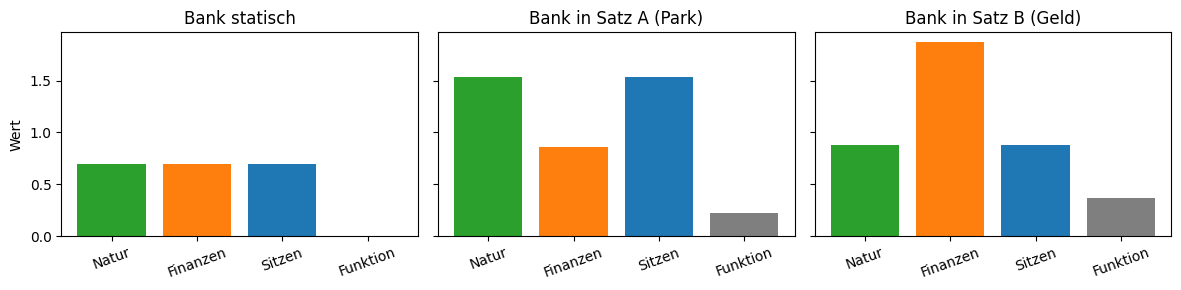

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3), sharey=True)
for ax, (titel, v) in zip(axes, [("statisch", x_bank), ("in Satz A (Park)", h_A), ("in Satz B (Geld)", h_B)]):
    ax.bar(dims, v, color=["tab:green", "tab:orange", "tab:blue", "tab:gray"])
    ax.set_title(f"Bank {titel}")
    ax.tick_params(axis="x", rotation=20)
axes[0].set_ylabel("Wert")
plt.tight_layout()
plt.show()

**Ergebnis:**

- Vorher sind beide „Bank“-Vektoren identisch (Kosinus 1.00).
- Nachher ist „Bank“ in Satz A deutlich näher an „Sofa“, in Satz B deutlich näher an „Konto“.
- Die beiden „Bank“-Vektoren haben sich voneinander entfernt: **Das Token ist dasselbe, die Bedeutung nicht mehr.**

## 4) Bezug zum Rechenbeispiel „von“ im Skript

Im Skript wird für „von“ aus $x_{\text{von}} = (1, 2, 1, 0)$ der Kontextvektor $(0.304,\ 0.529,\ 0.603,\ 0.399)$ berechnet.
Das ist nur der **Attention-Anteil**. Im echten Transformer kommt die Residual-Verbindung dazu, so wie oben bei „Bank“.

In [7]:
x_von = np.array([1, 2, 1, 0], dtype=float)
kontext_von = np.array([0.304, 0.529, 0.603, 0.399])   # Ergebnis aus dem Skript
h_von = x_von + kontext_von

print("x_von (statisch):         ", x_von)
print("Attention-Anteil (Skript):", kontext_von)
print("mit Residual:             ", h_von)

x_haupt = np.array([0, 1, 3, 1], dtype=float)           # Hauptstadt aus dem Skript
print(f"\nÄhnlichkeit zu 'Hauptstadt': statisch {cos_sim(x_von, x_haupt):.2f}, mit Kontext {cos_sim(h_von, x_haupt):.2f}")

x_von (statisch):          [1. 2. 1. 0.]
Attention-Anteil (Skript): [0.304 0.529 0.603 0.399]
mit Residual:              [1.304 2.529 1.603 0.399]

Ähnlichkeit zu 'Hauptstadt': statisch 0.62, mit Kontext 0.71


Auch hier rückt „von“ durch den Kontext näher an „Hauptstadt“, das Token mit dem größten Attention-Gewicht.
Das Residual sorgt dafür, dass die ursprüngliche Bedeutung des Tokens nicht verloren geht. Der Kontext wird **dazugerechnet**, nicht ersetzt.

## 5) *(Optional)* Gegenprobe mit einem echten Sprachmodell

Funktioniert das auch in einem echten Modell? Wir nehmen das deutsche GPT-2 von der Bayerischen Staatsbibliothek (`dbmdz/german-gpt2`, 12 Schichten, 768 Dimensionen) und lassen es acht Sätze lesen, die alle auf „Bank“ enden:
vier mit der Sitzbank, vier mit dem Geldinstitut.

Für jede Schicht nehmen wir den Vektor von „Bank“ und vergleichen:

- Ähnlichkeit zwischen Sätzen **mit gleicher Bedeutung**
- Ähnlichkeit zwischen Sätzen **mit verschiedener Bedeutung**

> Beim ersten Start werden ca. 500 MB heruntergeladen. In Colab ist `transformers` schon installiert; lokal ggf. `pip install transformers torch`.

In [8]:
try:
    import torch
    from transformers import AutoTokenizer, AutoModel
    MODELL_OK = True
except ImportError:
    MODELL_OK = False
    print("transformers/torch nicht installiert – Abschnitt 5 wird übersprungen.")

if MODELL_OK:
    name = "dbmdz/german-gpt2"
    tok = AutoTokenizer.from_pretrained(name)
    modell = AutoModel.from_pretrained(name, output_hidden_states=True).eval()

    park = ["Im Park sitze ich gern auf der Bank",
            "Nach dem Spaziergang ruhten wir uns auf einer Bank",
            "Die alte Frau füttert die Tauben von ihrer Bank",
            "Im Garten steht unter dem Baum eine hölzerne Bank"]
    geld = ["Mein Erspartes liegt sicher auf der Bank",
            "Für den Kredit ging ich zur Bank",
            "Die Überweisung kam pünktlich von der Bank",
            "Die Zinsen für mein Konto zahlt die Bank"]
    saetze = park + geld
    bedeutung = [0] * len(park) + [1] * len(geld)

    alle_tokens, bank_vektoren = [], []
    for s in saetze:
        ids = tok(s, return_tensors="pt")
        assert tok.convert_ids_to_tokens(ids["input_ids"][0])[-1] == "ĠBank", s
        with torch.no_grad():
            hidden = modell(**ids).hidden_states          # 13 Tensoren: Embedding + 12 Schichten
        alle_tokens.append([h[0].numpy() for h in hidden])
        bank_vektoren.append([h[0, -1].numpy() for h in hidden])

    print("Tokens Satz 1:", tok.convert_ids_to_tokens(tok(saetze[0])["input_ids"]))

Tokens Satz 1: ['Im', 'ĠPark', 'Ġsitze', 'Ġich', 'Ġgern', 'Ġauf', 'Ġder', 'ĠBank']


**Erster Check:** Das *rohe* Token-Embedding von „Bank“ (die Zeile in der Embedding-Matrix) ist natürlich in allen Sätzen identisch. Es ist schließlich dieselbe Token-ID.

In [9]:
if MODELL_OK:
    bank_id = tok.convert_tokens_to_ids("ĠBank")
    E_matrix = modell.get_input_embeddings().weight.detach().numpy()
    print("Token-ID von ' Bank':", bank_id)
    print("Embedding-Matrix:", E_matrix.shape, "(Vokabular × Dimensionen)")
    print("Erste 8 Werte des rohen Embeddings:", E_matrix[bank_id][:8].round(3))

Token-ID von ' Bank': 3346
Embedding-Matrix: (50265, 768) (Vokabular × Dimensionen)
Erste 8 Werte des rohen Embeddings: [ 0.378  0.068  0.098  0.207  0.258 -0.069 -0.261  0.043]


**Eine Hürde:** Die Hidden States von GPT-2 zeigen alle grob in **dieselbe Richtung**. Roh verglichen liegt die Kosinus-Ähnlichkeit fast immer über 0.9, egal welche Wörter man vergleicht (Fachbegriff: *Anisotropie*).
Deshalb ziehen wir pro Schicht den Mittelwert über alle Tokens ab (**Zentrieren**) und vergleichen erst dann.

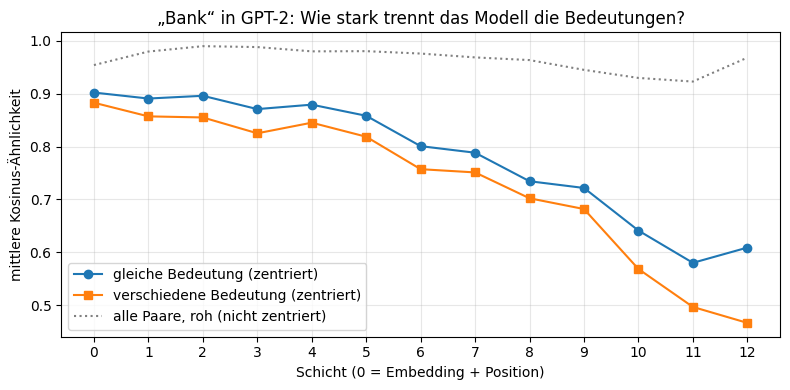

Schicht  0: gleiche Bedeutung 0.90, verschiedene 0.88, Abstand +0.02
Schicht  6: gleiche Bedeutung 0.80, verschiedene 0.76, Abstand +0.04
Schicht 12: gleiche Bedeutung 0.61, verschiedene 0.47, Abstand +0.14


In [10]:
if MODELL_OK:
    n_schichten = len(bank_vektoren[0])
    n = len(saetze)
    gleich, verschieden, roh = [], [], []
    for L in range(n_schichten):
        mu = np.concatenate([t[L] for t in alle_tokens]).mean(axis=0)
        V = [b[L] - mu for b in bank_vektoren]
        g = [cos_sim(V[i], V[j]) for i in range(n) for j in range(i + 1, n) if bedeutung[i] == bedeutung[j]]
        v = [cos_sim(V[i], V[j]) for i in range(n) for j in range(i + 1, n) if bedeutung[i] != bedeutung[j]]
        r = [cos_sim(bank_vektoren[i][L], bank_vektoren[j][L]) for i in range(n) for j in range(i + 1, n)]
        gleich.append(np.mean(g)); verschieden.append(np.mean(v)); roh.append(np.mean(r))

    plt.figure(figsize=(8, 4))
    plt.plot(gleich, "o-", label="gleiche Bedeutung (zentriert)")
    plt.plot(verschieden, "s-", label="verschiedene Bedeutung (zentriert)")
    plt.plot(roh, ":", color="gray", label="alle Paare, roh (nicht zentriert)")
    plt.xlabel("Schicht (0 = Embedding + Position)")
    plt.ylabel("mittlere Kosinus-Ähnlichkeit")
    plt.title("„Bank“ in GPT-2: Wie stark trennt das Modell die Bedeutungen?")
    plt.xticks(range(n_schichten))
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    for L in [0, 6, n_schichten - 1]:
        print(f"Schicht {L:>2}: gleiche Bedeutung {gleich[L]:.2f}, verschiedene {verschieden[L]:.2f}, Abstand {gleich[L] - verschieden[L]:+.2f}")

**Beobachtung:**

- In **Schicht 0** sind die „Bank“-Vektoren fast gleich ähnlich, egal welche Bedeutung gemeint ist. Kleine Unterschiede kommen nur vom Positional Encoding, weil „Bank“ nicht in allen Sätzen an derselben Stelle steht.
- Mit jeder Schicht wächst der **Abstand** zwischen den beiden Kurven. Das Modell trennt die Bedeutungen immer deutlicher.
- Ein Modell wie GPT-2 sieht nur die Wörter **vor** „Bank“ (Causal Mask). Ein bidirektionales Modell wie BERT würde auch den Rest des Satzes nutzen.

Zum Schluss projizieren wir die acht „Bank“-Vektoren der letzten Schicht mit PCA auf 2D:

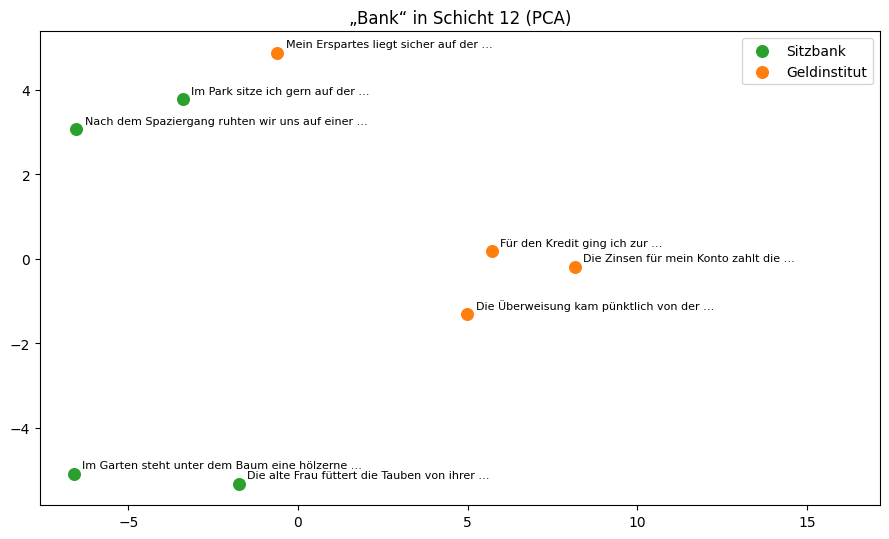

In [11]:
if MODELL_OK:
    L = n_schichten - 1
    mu = np.concatenate([t[L] for t in alle_tokens]).mean(axis=0)
    V = np.stack([b[L] - mu for b in bank_vektoren])
    Vc = V - V.mean(axis=0)
    _, _, Vt = np.linalg.svd(Vc, full_matrices=False)
    P = Vc @ Vt[:2].T

    plt.figure(figsize=(9, 5.5))
    for k, (farbe, label) in enumerate([("tab:green", "Sitzbank"), ("tab:orange", "Geldinstitut")]):
        sel = [i for i in range(n) if bedeutung[i] == k]
        plt.scatter(P[sel, 0], P[sel, 1], s=70, color=farbe, label=label)
    for i, s in enumerate(saetze):
        kurz = s.rsplit(" ", 1)[0] + " …"
        plt.annotate(kurz, P[i], textcoords="offset points", xytext=(6, 4), fontsize=8)
    plt.title(f"„Bank“ in Schicht {L} (PCA)")
    plt.xlim(P[:, 0].min() - 1, P[:, 0].max() + 9)
    plt.legend()
    plt.tight_layout()
    plt.show()

Die meisten Sätze landen bei ihrer Bedeutung, aber nicht alle. Je nach Satz kann ein „Ausreißer“ auf der falschen Seite liegen, etwa *„Mein Erspartes liegt sicher auf der Bank“*.
Das ist ehrlich: GPT-2 ist ein kleines Modell, sieht nur die Wörter **vor** „Bank“, und die 2D-Projektion wirft viel Information weg. Die Kurven oben (Mittelwerte über alle Paare) sind deshalb aussagekräftiger als einzelne Punkte.

## 6) Aufgaben

1. **Von Hand:** Berechne die Attention-Gewichte für „Bank“ in Satz B und prüfe sie mit der Ausgabe in Abschnitt 2.
2. **Ohne Residual:** Ersetze in `self_attention` die Zeile `H = X + A @ X` durch `H = A @ X`. Was ändert sich an den Ähnlichkeiten zu „Sofa“ und „Konto“?
3. **Mehrdeutiger Satz:** Baue einen Satz, in dem „Bank“ ungefähr gleich nah an „Sofa“ und „Konto“ bleibt.
4. *(Optional, Abschnitt 5)* Ergänze eigene Sätze, etwa einen mehrdeutigen wie *„Ich wartete lange vor der Bank“*. Wo landet er in der PCA?

---

### Take-away
**Self-Attention verwandelt statische Wort-Embeddings in kontextualisierte Bedeutungen.** Dasselbe Token startet überall gleich und wird erst durch die Nachbarn im Satz eindeutig.